# 4. Neural Networks with PyTorch

In this notebook we build our first neural network with `PyTorch`.
For this you must first install PyTorch as described [here](https://pytorch.org/get-started/locally/).

We will work on the same dataset as the last two last weeks and try to predict which digit is shown on the given pixel values.

In [414]:
from sklearn.datasets import fetch_openml
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, cache=True, parser='auto')

We know already from last time how the data looks:

In [415]:
X.head(3)

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The label is a number between 0-9 representing the digit shown on the pixels.

In [416]:
y.head(3)

0    5
1    0
2    4
Name: class, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

Before we start, we scale the data and divide it into train and test data:

In [417]:
from sklearn.model_selection import train_test_split

X_scaled = (X/255).astype('float32').values
y = y.astype('long').values
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.15, random_state=42)
X_train.shape, y_train.shape

((59500, 784), (59500,))

###  Model Training

The following lines checks for the availability of a GPU on the machine and sets the GPU as processing device (if available). No worries if you have no GPU available, CPU works also fine for our examples.

In [418]:
import torch
torch.manual_seed(0) # to ensure reproducibility

In [419]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"Using {device} device")
else:
    print ("MPS device not found.")

Using mps device


To be able to use the data in PyTorch, we need to convert our data into PyTorch tensors.
Such a tensor is the PyTorch equivalent of a Numpy array. 
However, it has the additional benefit that they can be easily copied to the GPU (the `.to(device)` part in the code below) and that they support automatic backpropagation (more on this later):

In [420]:
train_x = torch.Tensor(X_train).float().to(device)
test_x = torch.Tensor(X_test).float().to(device)
train_y = torch.Tensor(y_train).long().to(device)
test_y = torch.Tensor(y_test).long().to(device)

We start with the following structure of a neural network with two hidden layers:
- Input layer of size 784
- First hidden layer of size 128 with sigmoid activation
- Second hidden layer of size 64 with sigmoid activation
- Output layer of size 10

A skeleton code for this network is given in the following class.

In [421]:
import torch.nn as nn

class DeepNeuralNetwork(nn.Module): # the class has to inherit from nn.Module
    def __init__(self):
        
        super(DeepNeuralNetwork, self).__init__()  # calling super constructor
        
        # defining layers
        self.hidden1 = nn.Linear(784, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 10)

    def forward(self, x):
        
        z1 = self.hidden1(x)
        a1 = torch.sigmoid(z1)
        z2 = self.hidden2(a1)
        a2 = torch.sigmoid(z2)
        z3 = self.output(a2)
        # note: we do not apply the softmax here!
        return z3

We can now create the model and move it to the device. We set it to `train` mode and check the number of parameters:

In [422]:
dnn = DeepNeuralNetwork()
print("Number of parameters:", sum(p.numel() for p in dnn.parameters())) 
dnn.to(device)            # copy the model to the device 
dnn.train()      # set model into training mode

Number of parameters: 109386


DeepNeuralNetwork(
  (hidden1): Linear(in_features=784, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=10, bias=True)
)

We can now start training the network by implementing the training procedure. We train the network for 1000 epochs:

In [423]:
no_epochs = 1000
learning_rate = 0.3

loss_func = nn.CrossEntropyLoss()  
optimizer = torch.optim.SGD(dnn.parameters(), lr=learning_rate)

losses = []
for iteration in range(no_epochs):
    
    optimizer.zero_grad()
    y_hat = dnn(train_x) # we predict on all data points (= batch gradient descent)
    
    loss = loss_func(y_hat, train_y) # calculate the loss
    loss.backward() # backpropagate the loss to calculate gradients
    optimizer.step() # update the weights using these gradients 

    losses.append(loss.item())
    if iteration % 100 == 0:
        print(f"Loss in epoch {iteration} is {loss.item()}")
           

Loss in epoch 0 is 2.3741440773010254
Loss in epoch 100 is 2.277350425720215
Loss in epoch 200 is 2.049368143081665
Loss in epoch 300 is 1.3549598455429077
Loss in epoch 400 is 0.9302160739898682
Loss in epoch 500 is 0.7136896252632141
Loss in epoch 600 is 0.5928159952163696
Loss in epoch 700 is 0.518756091594696
Loss in epoch 800 is 0.4688713252544403
Loss in epoch 900 is 0.43262410163879395


Text(0, 0.5, 'loss')

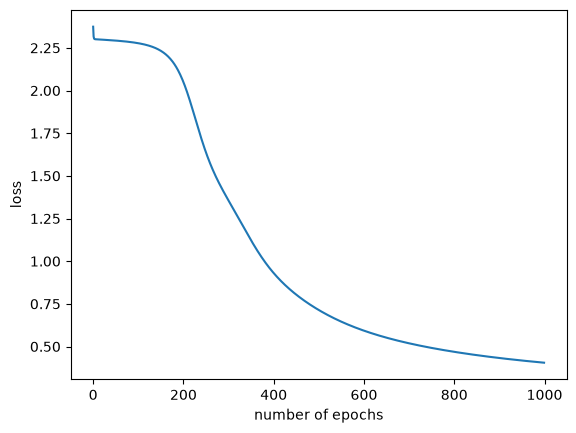

In [424]:
import matplotlib.pyplot as plt
fig = plt.figure()
plt.plot(range(0, no_epochs), losses)
plt.xlabel('number of epochs')
plt.ylabel('loss')

### Predict on the test data

After the network is trained, we can use it to predict on the test data.

In [425]:
dnn.eval() 
y_pred = dnn(test_x)
predicted = torch.argmax(y_pred.data, 1)
correct = (predicted == test_y).sum().item()
accuracy = correct / len(test_x)

print(f"Accuracy is {100. * accuracy}%")

Accuracy is 88.28571428571429%


If we want to prediction of the network on a data point, we get the raw scores since we did not use a softmax activation layer in the output layer:

In [426]:
dnn(test_x[0])

tensor([-3.2510, -0.2967,  0.9061,  2.3132, -2.3849,  2.5244, -3.1187, -2.9709,
         6.9886,  0.9822], device='mps:0', grad_fn=<LinearBackward0>)

We can get the probabilities by applying a softmax to this output:

In [427]:
import torch.nn.functional as F
y_hat = dnn(test_x[0])
F.softmax(y_hat, dim=0)

tensor([3.4806e-05, 6.6785e-04, 2.2235e-03, 9.0811e-03, 8.2754e-05, 1.1216e-02,
        3.9729e-05, 4.6054e-05, 9.7421e-01, 2.3993e-03], device='mps:0',
       grad_fn=<SoftmaxBackward0>)

The maximum index is in both cases the same, since the softmax does not change the ranking of the values.

In [428]:
x1 = dnn(test_x[0]) # raw scores
x2 = F.softmax(dnn(test_x[0]), dim=0) # probabilites
print(torch.argmax(x1))
print(torch.argmax(x2))

tensor(8, device='mps:0')
tensor(8, device='mps:0')


## Coding Tasks

### 1. Prepare the data
1. Create a new notebook in which you load the titanic dataset (see `data` folder).
2. Keep the following columns, filter out the rest: `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Survived`.
3. Drop all NAs values using: `df = df.dropna()`
4. One-hot encode the attributes `Sex` and `Embarked` using the following code:
    `df = pd.get_dummies(df, columns=["Sex", "Embarked"], dtype=float)`
5. Take `survived` as label and the other columns as features.
6. Do a train-test-split with 20% test data and set `random_state=0`
7. Standardize the features. Fit the scaler on the training data only, then apply it to both sets.

#### 1.1 Load Dataset

In [429]:
import pandas as pd
data = pd.read_csv("data/titanic.csv")
print(data.shape)
data.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### 1.2

In [430]:

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]
data_features = data[features]
data_features.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


#### 1.3

In [431]:
df = data_features.dropna()

print(f"With NaN Values: {data_features.size}")
print(f"Cleaned: {df.size}")


With NaN Values: 7128
Cleaned: 5696


#### 1.4

In [432]:
df = pd.get_dummies(df, columns=["Sex", "Embarked"], dtype=float)

#### 1.5

In [433]:
x = df.drop(columns="Survived")
y = df["Survived"]

#### 1.6

In [434]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

print("Train data points:", len(X_train))
print("Test data points:", len(X_test))

Train data points: 569
Test data points: 143


#### 1.7

In [435]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2. Train a neural network
1. Train a neural network with one hidden layer of size 5 and ReLu as activation for this layer (no activation on the output layer).
2. Use `CrossEntropyLoss` and a `SGD` optimizer with learning rate 0.001
3. Train the network for 200 epochs and print the loss every 20 epochs.
4. Plot the loss plot as shown above.
5. Predict on the test data with the trained network and measure accuracy.

#### 2.1 Train a neural network with one hidden layer of size 5 and ReLu as activation for this layer (no activation on the output layer).

In [436]:
import torch.nn as nn
    
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(10, 5),
            nn.ReLU(),
            nn.Linear(5, 2),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [437]:
y_train = y_train.values
y_test = y_test.values
train_x = torch.Tensor(X_train_scaled).float().to(device)
test_x = torch.Tensor(X_test_scaled).float().to(device)
train_y = torch.Tensor(y_train).long().to(device)
test_y = torch.Tensor(y_test).long().to(device)

#### 2.2 Use `CrossEntropyLoss` and a `SGD` optimizer with learning rate 0.001
#### 2.3 Train the network for 200 epochs and print the loss every 20 epochs.

In [438]:
from torch.nn import CrossEntropyLoss

dnn = NeuralNetwork()
dnn.to(device)
dnn.train(True)

no_epochs = 200
learning_rate = 0.001

loss_func = CrossEntropyLoss()
optimizer = torch.optim.SGD(dnn.parameters(), lr=learning_rate)

losses = []

for iteration in range(no_epochs):
    
    optimizer.zero_grad()
    y_hat = dnn(train_x) # we predict on all data points (= batch gradient descent)
    
    loss = loss_func(y_hat, train_y) # calculate the loss
    loss.backward() # backpropagate the loss to calculate gradients
    optimizer.step() # update the weights using these gradients 

    losses.append(loss.item())
    if iteration % 20 == 0:
        print(f"Loss in epoch {iteration} is {loss.item()}")

Loss in epoch 0 is 0.6361298561096191
Loss in epoch 20 is 0.6352359652519226
Loss in epoch 40 is 0.6343451738357544
Loss in epoch 60 is 0.6334558129310608
Loss in epoch 80 is 0.6325730085372925
Loss in epoch 100 is 0.6316960453987122
Loss in epoch 120 is 0.6308294534683228
Loss in epoch 140 is 0.629967987537384
Loss in epoch 160 is 0.6291131377220154
Loss in epoch 180 is 0.6282635927200317


#### 2.4 Plot the loss plot as shown above.

Text(0, 0.5, 'loss')

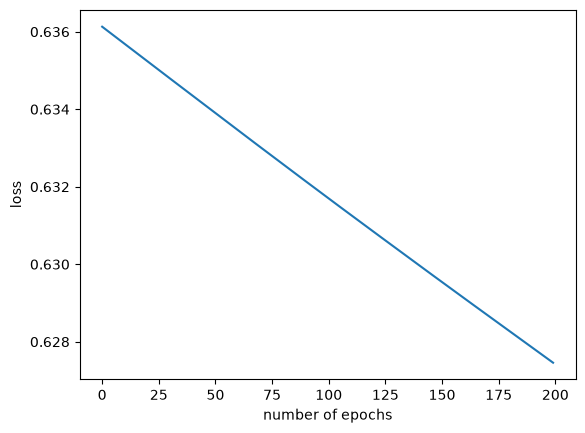

In [439]:
import matplotlib.pyplot as plt
fig = plt.figure()
plt.plot(range(0, no_epochs), losses)
plt.xlabel('number of epochs')
plt.ylabel('loss')

#### 2.5 Predict on the test data with the trained network and measure accuracy.

In [440]:
def eval_dnn(dnn, data_x, data_y, acc_list = None, print_acc=True):
    dnn.eval() 
    y_pred = dnn(data_x)
    predicted = torch.argmax(y_pred.data, 1)
    correct = (predicted == data_y).sum().item()
    accuracy = correct / len(data_x)
    
    if acc_list is not None:
        acc_list.append(accuracy)

    if print_acc:
        print(f"Accuracy is {100. * accuracy}%")
    
eval_dnn(dnn, test_x, test_y)


Accuracy is 57.34265734265735%


### 3. Overfitting
- After each epoch, use the network to predict on the train data and on the test data. Measure the accuracy on both and remember the values in separate lists.
- After the training is finished, plot both curves in a graph with number of epochs on the x-axis and accuracy on y.
- Does the graph indicate overfitting of the model?

In [441]:
acc_train = []
acc_test = []

In [442]:
from torch.nn import CrossEntropyLoss

dnn = NeuralNetwork()
dnn.to(device)
dnn.train(True)

no_epochs = 200
learning_rate = 0.01

loss_func = CrossEntropyLoss()
optimizer = torch.optim.SGD(dnn.parameters(), lr=learning_rate)

losses = []

for epoch in range(no_epochs):
    
    optimizer.zero_grad()
    y_hat = dnn(train_x) # we predict on all data points (= batch gradient descent)
    
    loss = loss_func(y_hat, train_y) # calculate the loss
    loss.backward() # backpropagate the loss to calculate gradients
    optimizer.step() # update the weights using these gradients 

    losses.append(loss.item())
    
    eval_dnn(dnn, train_x, train_y, acc_train, print_acc=False)
    eval_dnn(dnn, test_x, test_y, acc_test, print_acc=False)
    if epoch % 20 == 0:
        print(f"Loss in epoch {epoch} is {loss.item()}")

Loss in epoch 0 is 0.7733181118965149
Loss in epoch 20 is 0.7451730966567993
Loss in epoch 40 is 0.724210798740387
Loss in epoch 60 is 0.708776593208313
Loss in epoch 80 is 0.6962112784385681
Loss in epoch 100 is 0.68567955493927
Loss in epoch 120 is 0.6765241026878357
Loss in epoch 140 is 0.6682527661323547
Loss in epoch 160 is 0.6606429219245911
Loss in epoch 180 is 0.6534109711647034


In [443]:
len(acc_train)

200

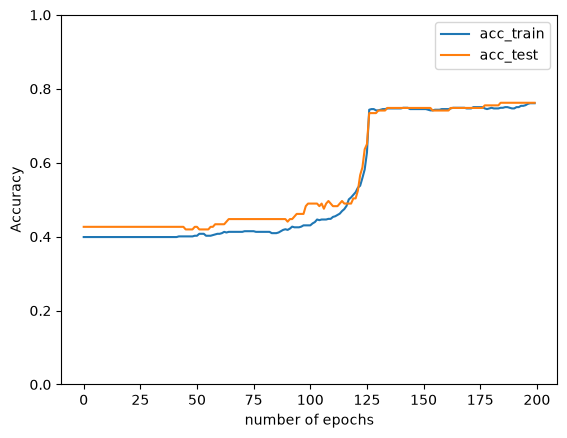

In [444]:
import matplotlib.pyplot as plt
fig = plt.figure()
plt.plot(range(0, no_epochs), acc_train, label="acc_train")
plt.plot(range(0, no_epochs), acc_test, label="acc_test")
plt.ylim(0, 1)

plt.xlabel('number of epochs')
plt.ylabel('Accuracy')
plt.legend()

Der Plot (lr= 0,01, epochen = 200) zeigt keine Anzeichen von Overfitting. Train- und Test Accuracy steigen gemeinsam und die Lücke zwischen den beiden Plots bleibt klein. 